In [7]:
%pip install statsmodels

  Using cached statsmodels-0.15.0-cp314-cp314-win_amd64.whl.metadata (9.6 kB)
  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached wrapt-2.6.0.dev1-cp314-cp314-win_amd64.whl.metadata (7.8 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ----------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [8]:
import pandas as pd
df=pd.read_csv("ice_cream_sales_2018_2023.csv")

In [9]:
df.head(16)

,date,sales
0,2018-01-31,118.476167
1,2018-02-28,140.641535
2,2018-03-31,163.151723
3,2018-04-30,165.561963
4,2018-05-31,127.213792
5,2018-06-30,51.496827
6,2018-07-31,21.261524
7,2018-08-31,25.818400
8,2018-09-30,17.459900
9,2018-10-31,17.652100


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    72 non-null     str    
 1   sales   72 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.3 KB


In [4]:
df["date"] = pd.to_datetime(df["date"])
df.dtypes

date     datetime64[us]
sales           float64
dtype: object

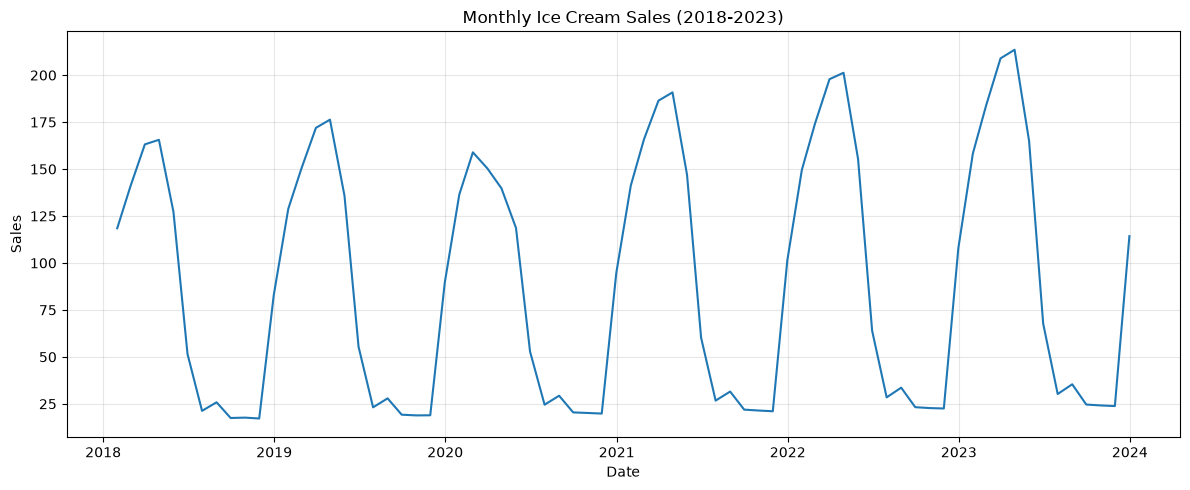

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data and parse the date column
df = pd.read_csv("ice_cream_sales_2018_2023.csv", parse_dates=["date"])
df = df.set_index("date")

# Plot
plt.figure(figsize=(12, 5))
plt.plot(df.index, df["sales"], markersize=3, linewidth=1.5, color="tab:blue")

plt.title("Monthly Ice Cream Sales (2018-2023)")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

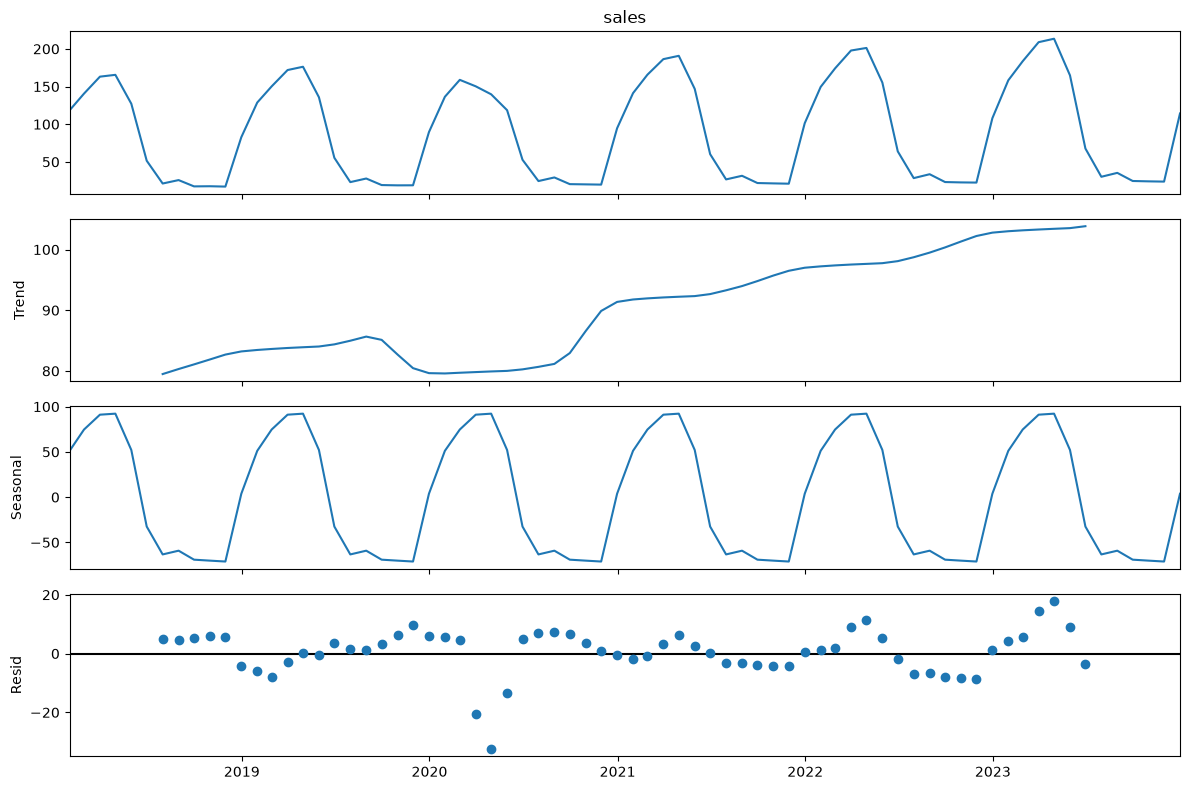

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load data
df = pd.read_csv("ice_cream_sales_2018_2023.csv", parse_dates=["date"])
df = df.set_index("date")

# Decompose (monthly data, so the seasonal period is 12)
result = seasonal_decompose(df["sales"], model="additive", period=12)

# Plot all four components
fig = result.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()